# What separates winning performances in the NBA, and can we predict them?

**Part 1, explain:** of the four things a team controls (shooting efficiency, turnovers, offensive rebounding,
free throws), which matters most for winning, and has the 3-point era changed it?

**Part 2, predict:** before tip-off, how well can a game be called, and do recent-form statistics add anything
beyond a team-strength rating?

The two parts answer different questions and use different information. Part 1 uses statistics *from* each
game, so it explains results but cannot forecast them. Part 2 uses only what is known before the game.

**Data.** Team box scores from the Kaggle dataset *Historical NBA Data and Player Box Scores* by Eoin A Moore,
pinned to version 552 (`python download_data.py`). All logic lives in the tested `nba_analytics` package
(`src/`); this notebook is the narrative.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nba_analytics import data, elo, features, models
from nba_analytics import four_factors as ff

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

## 0. Data quality

`prepare_games` keeps complete seasons, removes games whose recorded result can't be trusted, then runs strict
validation (two rows per game, one winner per game, the winner scored more, no more shots made than attempted).
Anything removed is reported here, not dropped silently.

In [2]:
games, report = data.prepare_games('data/TeamStatistics.csv', first=2001, last=2024)
print(f"{report['games']:,} games kept across {len(report['seasons_kept'])} seasons "
      f"({report['seasons_kept'][0]} to {report['seasons_kept'][-1]})")
print('Seasons dropped as incomplete in the source (games present):', report['seasons_dropped'])
report['games_dropped_inconsistent']

27,597 games kept across 23 seasons (2001-02 to 2024-25)
Seasons dropped as incomplete in the source (games present): {'2021-22': 1}


,gameId,date,matchup,reason
0,20400090,2004-11-13,Trail Blazers (home),tied final score (overtime points missing)
1,21000028,2010-10-29,Mavericks (home),tied final score (overtime points missing)
2,22400627,2025-03-19,Jazz (home),score recorded as 0-0
3,22400988,2025-04-01,Spurs (home),score recorded as 0-0


The source has only one game from 2021-22, so that season is excluded (2000-01, which has half its games, is
outside the window by choice). The four removed games either have a tied final score, impossible in the NBA, so
overtime points are missing, or are recorded as 0-0.

In [3]:
team_games = ff.add_four_factors(games)          # one row per team per game
home = data.home_view(games)                      # one row per game, home team's view
home_ff = home.merge(team_games.loc[team_games['home'] == 1, ['gameId'] + ['diff_' + f for f in ff.FACTORS]], on='gameId')
print(f"Home teams won {home['win'].mean():.1%} of games")

Home teams won 58.7% of games


# Part 1: what separates winners from losers?

## 1.1 How often does the team that wins each factor win the game?

In [4]:
win_rate = ff.factor_win_rates(home_ff).rename(ff.LABELS).round(1)
win_rate

Shooting (eFG%)           81.0
Turnovers (TOV%)          56.3
Off. rebounding (ORB%)    56.5
Free throws (FT rate)     59.9
dtype: float64

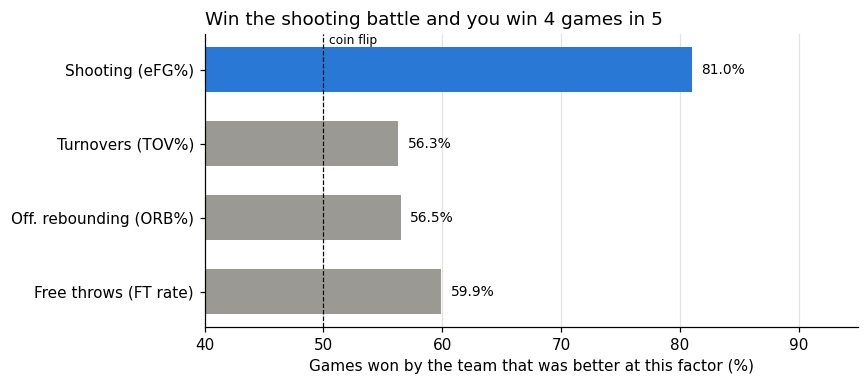

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(win_rate.index[::-1], win_rate.values[::-1], color=[GREY, GREY, GREY, BLUE], height=0.6)
ax.axvline(50, color=INK, lw=0.8, ls='--'); ax.text(50.5, 3.35, 'coin flip', fontsize=8)
for y, v in enumerate(win_rate.values[::-1]):
    ax.text(v + 0.8, y, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(40, 95); ax.set_xlabel('Games won by the team that was better at this factor (%)')
ax.set_title('Win the shooting battle and you win 4 games in 5'); ax.grid(axis='y', visible=False)
save(fig, '01_factor_win_rates.png')

## 1.2 How much does each factor matter, holding the others equal?

Logistic regression of the result on the four factor gaps, each standardised so the coefficients are comparable.

In [6]:
weights = models.fit_factor_weights(home_ff)
weights["Oliver's estimate %"] = list(ff.OLIVER_WEIGHTS.values())
weights.round(2)

,coefficient_per_sd,relative_weight_pct,Oliver's estimate %
Shooting (eFG%),8.87,46.93,40
Turnovers (TOV%),-4.25,22.46,25
Off. rebounding (ORB%),3.22,17.01,20
Free throws (FT rate),2.57,13.60,15


## 1.3 Has the 3-point era changed the weights?

In [7]:
three_share = games.groupby('season').apply(lambda g: g['threePointersAttempted'].sum() / g['fieldGoalsAttempted'].sum() * 100)
eras = pd.DataFrame({
    '2001-02 to 2011-12': models.fit_factor_weights(home_ff[home_ff['season'].between(2001, 2011)])['relative_weight_pct'],
    '2013-14 to 2024-25': models.fit_factor_weights(home_ff[home_ff['season'].between(2013, 2024)])['relative_weight_pct'],
}).round(1)
print(f"3-pointers as a share of all shots: {three_share.loc[2001]:.0f}% in 2001-02 -> {three_share.loc[2024]:.0f}% in 2024-25")
eras

3-pointers as a share of all shots: 18% in 2001-02 -> 42% in 2024-25


,2001-02 to 2011-12,2013-14 to 2024-25
Shooting (eFG%),45.6,48.3
Turnovers (TOV%),22.5,22.3
Off. rebounding (ORB%),17.0,17.1
Free throws (FT rate),14.8,12.3


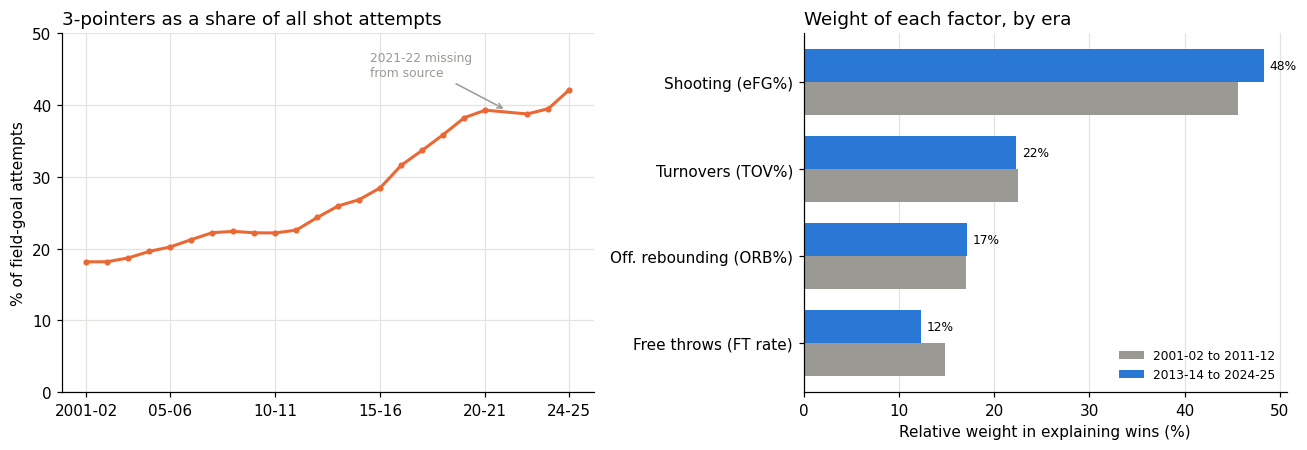

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.1, 1]})
a.plot(three_share.index, three_share.values, color=ORANGE, lw=2, marker='o', ms=3)
a.annotate('2021-22 missing\nfrom source', (2021, three_share.loc[2020]), xytext=(2014.5, 44), fontsize=8, color=GREY,
           arrowprops=dict(arrowstyle='->', color=GREY))
a.set_title('3-pointers as a share of all shot attempts'); a.set_ylabel('% of field-goal attempts'); a.set_ylim(0, 50)
a.set_xticks([2001, 2005, 2010, 2015, 2020, 2024], ['2001-02', '05-06', '10-11', '15-16', '20-21', '24-25'])
y = np.arange(len(eras)); h = 0.38
b.barh(y + h / 2, eras.iloc[:, 0], h, color=GREY, label=eras.columns[0])
b.barh(y - h / 2, eras.iloc[:, 1], h, color=BLUE, label=eras.columns[1])
for i in range(len(eras)):
    b.text(eras.iloc[i, 1] + 0.6, i - h / 2, f'{eras.iloc[i, 1]:.0f}%', va='center', fontsize=8)
b.set_yticks(y, eras.index); b.invert_yaxis(); b.set_xlabel('Relative weight in explaining wins (%)')
b.set_title('Weight of each factor, by era'); b.legend(frameon=False, loc='lower right', fontsize=8); b.grid(axis='y', visible=False)
save(fig, '02_three_point_era.png')

# Part 2: can games be predicted before tip-off?

**Protocol.** Seasons are split by time, never at random, because a model must be judged on the future:

| Split | Seasons | Used for |
|---|---|---|
| Train | 2001-02 to 2016-17 | Fitting models; tuning Elo's K and home bonus |
| Validation | 2017-18 to 2019-20 | Choosing between model designs |
| Test | 2020-21, 2022-23 to 2024-25 | Reported once, at the end |

Forecasts are scored on **log loss** and **Brier score** (quality of the probabilities) as well as accuracy.

## 2.1 Home advantage has shrunk

A team-strength rating needs a home-court bonus. Home win rates show that bonus is not constant:

Home win rate: 60.4% in 2001-02 to 2010-11, 55.3% from 2019-20 on


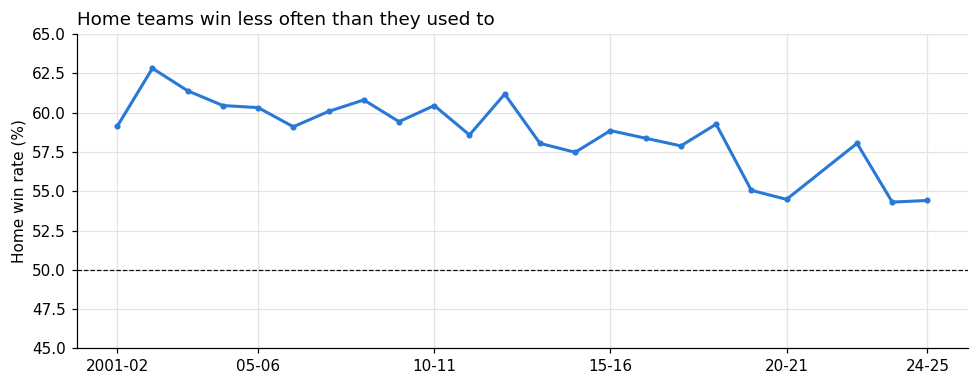

In [9]:
home_rate = home.groupby('season')['win'].mean() * 100
print(f"Home win rate: {home_rate.loc[2001:2010].mean():.1f}% in 2001-02 to 2010-11, "
      f"{home_rate.loc[2019:].mean():.1f}% from 2019-20 on")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(home_rate.index, home_rate.values, color=BLUE, lw=2, marker='o', ms=3)
ax.axhline(50, color=INK, lw=0.8, ls='--')
ax.set_ylim(45, 65); ax.set_ylabel('Home win rate (%)'); ax.set_title('Home teams win less often than they used to')
ax.set_xticks([2001, 2005, 2010, 2015, 2020, 2024], ['2001-02', '05-06', '10-11', '15-16', '20-21', '24-25'])
save(fig, '03_home_advantage.png')

## 2.2 Elo ratings: tune on train, choose the design on validation

Elo gives every team a rating that moves after each game (see `src/nba_analytics/elo.py`). Two designs:
a **fixed** home bonus, or an **adaptive** one re-estimated each season from the previous three seasons' home win
rate (past data only). K and the fixed bonus are tuned on the training seasons; the design is chosen on validation.

In [10]:
best_fixed, grid = elo.tune_elo(home, seasons=(2003, 2016),   # 2001-02 and 02-03 are warm-up
                                 grid={'k': [15, 20, 25], 'home_advantage': [60, 80, 100]})
print('Tuned on training seasons:', best_fixed)

designs = {'Fixed home bonus': best_fixed,
           'Adaptive home bonus': elo.EloParams(k=best_fixed.k, home_advantage=best_fixed.home_advantage, adaptive_home=True)}
validation = home['season'].between(2017, 2019)
rows = []
for name, params in designs.items():
    p = elo.run_elo(home, params)['p_home_elo']
    rows.append({'design': name, **models.score(home.loc[validation, 'win'], p[validation].to_numpy()),
                 'mean predicted home win': p[validation].mean(), 'actual home win': home.loc[validation, 'win'].mean()})
choice = pd.DataFrame(rows).set_index('design')
chosen = choice['log_loss'].idxmin()
print('Chosen on validation:', chosen)
choice.round(4)

Tuned on training seasons: EloParams(k=15.0, home_advantage=80.0, season_regression=0.25, initial=1500.0, adaptive_home=False, home_lookback=3)


Chosen on validation: Adaptive home bonus


,accuracy,log_loss,brier,auc,mean predicted home win,actual home win
design,,,,,,
Fixed home bonus,0.6516,0.6214,0.2159,0.7004,0.5933,0.5757
Adaptive home bonus,0.6508,0.6206,0.2157,0.7001,0.5679,0.5757


## 2.3 Do recent-form statistics add anything beyond Elo?

In [11]:
elo_ratings = elo.run_elo(home, designs[chosen])
pregame = features.pregame_features(home, team_games, elo_ratings, window=10)
split = models.time_split(pregame, train_last=2016, validation_last=2019)
results, fitted = models.evaluate_predictors(pregame, features.FEATURES, split)
results.round(4)

games  accuracy  log_loss  \
split      model                                                          
test       Elo rating only                     4648    0.6381    0.6314   
           Gradient boosting (Elo + form)      4648    0.6433    0.6348   
           Home team always wins (base rate)   4648    0.5544    0.6911   
           Logistic regression (Elo + form)    4648    0.6450    0.6302   
validation Elo rating only                     3296    0.6517    0.6199   
           Gradient boosting (Elo + form)      3296    0.6502    0.6224   
           Home team always wins (base rate)   3296    0.5740    0.6833   
           Logistic regression (Elo + form)    3296    0.6514    0.6178   

                                               brier     auc  
split      model                                              
test       Elo rating only                    0.2208  0.6893  
           Gradient boosting (Elo + form)     0.2218  0.6898  
           Home team always wins (base rate)  0.2489  0.5000  
           Logistic regression (Elo + form)   0.2203  0.6936  
validation Elo rating only                    0.2154  0.7020  
           Gradient boosting (Elo + form)     0.2163  0.6988  
           Home team always wins (base rate)  0.2451  0.5000  
           Logistic regression (Elo + form)   0.2146  0.7034

In [12]:
y_test = fitted['parts']['test']['win']
preds = fitted['predictions']
gaps = {name: models.bootstrap_metric_gap(y_test, preds[name]['test'], preds['Elo rating only']['test'], 'log_loss', n_boot=1000)
        for name in ['Logistic regression (Elo + form)', 'Gradient boosting (Elo + form)']}
pd.DataFrame(gaps, index=['log-loss gap vs Elo', '95% CI low', '95% CI high']).T.round(4)

,log-loss gap vs Elo,95% CI low,95% CI high
Logistic regression (Elo + form),-0.0012,-0.0045,0.0022
Gradient boosting (Elo + form),0.0034,-0.0004,0.0075


A negative gap means better than Elo. If the 95% interval includes zero, the extra features have not shown a
reliable improvement on the test seasons.

In [13]:
coefs = pd.Series(fitted['models']['Logistic regression (Elo + form)'][-1].coef_[0], index=features.FEATURES)
coefs.sort_values().round(3).rename('standardised coefficient')

def_orb_gap   -0.047
off_tov_gap   -0.028
def_efg_gap   -0.012
home_b2b      -0.009
def_ftr_gap    0.011
away_b2b       0.022
off_orb_gap    0.023
off_ftr_gap    0.032
def_tov_gap    0.046
off_efg_gap    0.070
rest_gap       0.076
elo_diff       0.792
Name: standardised coefficient, dtype: float64

## 2.4 Are the probabilities trustworthy? Calibration on the test seasons

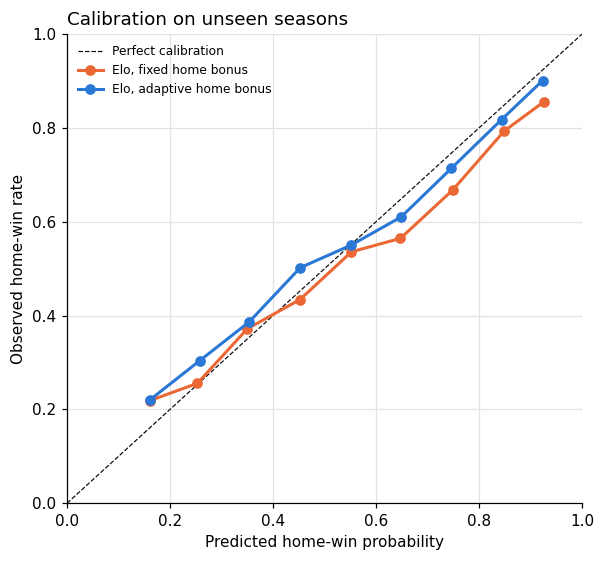

Mean predicted home win on test: fixed 0.595, adaptive home bonus 0.552, actual 0.554


In [14]:
fixed_p = elo.run_elo(home, designs['Fixed home bonus'])['p_home_elo']
test_games = fitted['parts']['test']
fixed_test = fixed_p.loc[home['gameId'].isin(test_games['gameId'])].to_numpy()
cal_fixed = models.calibration_table(test_games['win'], fixed_test)
cal_chosen = models.calibration_table(test_games['win'], preds['Elo rating only']['test'])

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=INK, lw=0.8, ls='--', label='Perfect calibration')
ax.plot(cal_fixed['predicted'], cal_fixed['observed'], color=ORANGE, lw=2, marker='o', label='Elo, fixed home bonus')
ax.plot(cal_chosen['predicted'], cal_chosen['observed'], color=BLUE, lw=2, marker='o', label=f'Elo, {chosen.lower()}')
ax.set_xlabel('Predicted home-win probability'); ax.set_ylabel('Observed home-win rate')
ax.set_title('Calibration on unseen seasons'); ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
save(fig, '04_calibration.png')
print(f"Mean predicted home win on test: fixed {fixed_test.mean():.3f}, {chosen.lower()} "
      f"{preds['Elo rating only']['test'].mean():.3f}, actual {test_games['win'].mean():.3f}")

## 3. Findings and recommendations

**Explaining results (Part 1)**
1. **Shooting efficiency decides most games.** The team with the better eFG% won about 81% of games; being better
   at any other single factor wins only 56-60%.
2. **The weights are close to Dean Oliver's 40/25/20/15**: shooting carries almost half, turnovers about a fifth.
3. **The 3-point era barely moved them**, despite 3-pointers more than doubling as a share of shots.

**Predicting results (Part 2)**
4. **About 64% of games can be called before tip-off**, against 55% for "the home team always wins". That ceiling
   is typical for NBA forecasting; the rest is genuine game-to-game randomness.
5. **Home advantage has shrunk**, from about 60% home wins in the 2000s to about 55% since 2019-20, so a rating
   with a fixed home bonus becomes overconfident about home teams. Re-estimating the bonus from recent seasons,
   using past data only, fixes the calibration.
6. **Recent-form statistics add no reliable signal beyond a calibrated Elo rating.** Their apparent edge over an
   uncalibrated Elo came from correcting its home-court bias, not from the form features themselves.

**Recommendation for a team or media analytics group:** use the simple, interpretable model: Elo with an adaptive
home bonus. It is as accurate as the more complex models, better understood and cheaper to run. To beat it, look
for information Elo doesn't contain (injuries, lineups, travel) rather than reprocessing box scores.

**Limitations.** Team box scores only (no injuries, lineups or shot locations); regular season only; the 2021-22
season is missing from the source.